# 🚀 Different work, or the same work with AI?
### Assignment after session 2 · Module 2

## Why this question

Around 1900, factories swapped their steam engines for electric motors and kept everything else as it was: the same shaft, the same belts, the same floor plan.
For about thirty years the figures barely moved. The gain came when firms redesigned the work around the new motor. So when a new technology spreads, the
interesting question is not how many people use it. It is whether the work itself changed.

Startups are at that point now. Since ChatGPT came out in November 2022, the share of new Y Combinator startups that describe AI as the core of what they sell has jumped. You will draw that
chart yourselves in step 1. The timing does not prove that ChatGPT caused it. And the jump can mean quite different things:

- **Story A, different work.** New startups go into other markets than the startups before them. In 2018 a new startup might build a food delivery app. In 2024 the new startups build tools for AI agents.
- **Story B, the same work with AI.** New startups go into the same markets as before and do the work in a new way. A new startup in 2018 sells bookkeeping to accountants. A new startup in 2024 does too, but AI reads the receipts.

Be clear about what we compare. Each YC batch is a new group of companies. We do not follow founders or companies over time, and nobody here has to change their mind.
We compare who is new in 2017–19 with who is new in 2023–26, as you might compare this year's students with those of five years ago.

Both stories produce the same rising line, so a chart of how often startups say "AI" cannot separate them. They are also not the only possibilities. Both can be partly true, and part of the rise may be
only a new label: the same work, described with AI because that helps to raise money. The analysis below can separate A from B, but it cannot fully rule out the label.

The difference matters, with one caution. YC is one selective US programme, so what you find holds for YC startups first, and not for the whole economy.

- **A founder or an investor.** Under story A there is a new market to enter. Under story B, AI competition is about to arrive in the market you are already in.
- **A worker or a manager.** Story A suggests AI stays a sector of its own. Story B suggests it could reach existing kinds of work, such as bookkeeping or legal work. New startups can only hint at this: they do not show what established firms do.
- **An economist.** Story B would fit a **general-purpose technology**: one that many industries adopt for their own work, as they did with electricity. Story A would fit a new industry.

So this is the question:

> **Did startups start doing different work, or do they do the same work as before, now with AI?**

## From the big question to smaller questions

No model can answer that directly. You cannot hand a model 5,500 startups and ask "is this story A?". The way forward is to ask what you would need to know.

To tell the stories apart, you need two facts about every startup: is AI the core of what it sells, and what work does it do? We measure these two facts **separately, on
purpose**. If they were mixed, the answer would be built in from the start. The split is never perfect: a type such as "AI agents" sits on the line, and you will have to decide how to treat it. With both facts in hand, you can count how they changed together.

That turns one big question into five smaller ones. Each is a different *kind* of question, and the kind of question decides the tool:

| Step | Smaller question | What kind of question is it? | Tool | Runs for |
|---|---|---|---|---|
| 1 | Is AI the core of this startup? | Yes or no. We can state it exactly, for 5,500 startups, and nobody has labelled them | Decision model | about 8 min |
| 2 | What work does it really do? | We need new text: marketing goes in, plain words come out | Small LLM, on a sample | about 5 min |
| 3 | Which types of work exist? | Nobody has a list yet, so there is nothing to choose from | BERTopic, with you as the judge | about 2 min |
| 4 | Which type is each startup? | Now there is a list, and 5,500 startups to sort | Classifier or decision model | about 12 min |
| 5 | How much of the rise happened inside the same types? | Counting. No text is left to read | Shift-share | seconds |

Each step hands something to the next:

```
                ┌─▶ 1 AI core? yes or no ───────────────────────────────┐
 description ───┤                                                       ├─▶ 5 shift-share ─▶ answer
                └─▶ 2 plain work ─▶ 3 types of work ─▶ 4 type of all ───┘
```

**Why not one tool for everything?**

- **A keyword search for "AI"** counts every startup that mentions AI once, and it cannot say what work a startup does.
- **A language model alone** could read everything, but one pass over all startups takes about 40 minutes per question on your GPU. On a free cloud key of 500 calls a day, one pass takes eleven days.
- **A classifier alone** needs labels, and nobody has labelled these startups.
- **A topic model alone** finds groups but does not know what AI is. Worse, startups that write "AI" in every sentence tend to land together, and you would "find" different work only because of how they describe themselves.
- **A decision model alone** can only choose from options you give it, and at the start you have no list of options. It also cannot rewrite anything.

**How it works.** The steps are given, you write the code in the cells marked ✏️. Each one has a hint and names the session notebook to copy from.
Setup, charts and the longer loops are done for you.

**Groups and submission.** Form your groups yourselves. Tryfonas will tell you later how to submit.

AI assistants are welcome for the code, but you must be able to explain every step. The checks by hand, the definitions and
your conclusion must be your own, because they are the point of the exercise.

**Before you start:** Runtime → Change runtime type → T4 GPU. Then run the cells one at a time.
If Colab asks for access to `HF_TOKEN`, click *Cancel*.

✏️ **Predict first.** Before you see any data, write down which story you expect, and why, in the text cell below. Then write what you would expect in the data under each story. Under story A, what happens to the
share of startups in each type of work? Under story B, what happens to the share of AI inside each type? You come back to this at the end.

[link text](https://)*Our prediction:*   We believe it would be a mix of story A and story B

**Own machine.** This notebook also runs in Jupyter or VS Code on a laptop with Ollama installed: Moodle explains how. Leave `BACKEND` on `ollama`.

**Plan B, if local does not work** (no free GPU, or Ollama fails). Create a free key at [aistudio.google.com](https://aistudio.google.com) and
store it as a Colab secret called `GEMINI_API_KEY` (key icon on the left, then switch on access for this notebook). In the setup cell, set `BACKEND`
to `gemini` and run everything again. A Groq key from [console.groq.com](https://console.groq.com), stored as `GROQ_API_KEY`, works the same way with `groq`.

The code stays the same and your texts go to the provider. Free keys allow few calls a minute and about 500 a day, so everyone needs their own key, and plan B runs on smaller samples and takes longer. Your numbers will differ from the slides, because the cloud model is stronger.

The cloud has no decision model, so here plan B replays saved answers from a real `d3:2b` run. Those parts run instantly, and new questions to the decision model do not work.

In [1]:
# @title Setup: install Ollama and download the models (2 to 4 minutes) { display-mode: "form" }
BACKEND = "ollama"  # @param ["ollama", "gemini", "groq"]
%pip install -q -U openai bertopic 2> /dev/null
import hashlib, json, os, random, shutil, subprocess, sys, time, warnings
from concurrent.futures import ThreadPoolExecutor
from typing import Literal, Optional
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
from openai import OpenAI
from pydantic import BaseModel, Field
from sklearn.metrics import accuracy_score, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.svm import LinearSVC
warnings.filterwarnings("ignore")

OLLAMA = "http://localhost:11434"
DECIDER = "d3:2b"
DEVICE = "cpu" if sys.platform == "darwin" else None   # on a Mac, Ollama already fills the GPU memory
if BACKEND == "ollama":
    if shutil.which("ollama") is None and "google.colab" in sys.modules:
        subprocess.run("apt-get -qq install -y zstd > /dev/null && curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1", shell=True)
    if shutil.which("ollama") is None:
        raise RuntimeError("Ollama is not installed. On your own machine, install it as described on Moodle. Otherwise use plan B: see the top of this notebook.")

    # start_new_session keeps the server alive when you stop a cell
    subprocess.Popen(["ollama", "serve"], start_new_session=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(4)
    for model in ["d3:2b", "gemma4:e2b"]:
        t0 = time.time()
        done = subprocess.run(["ollama", "pull", model], capture_output=True)
        print(f"{model} ready ({time.time() - t0:.0f} s)" if done.returncode == 0 else f"{model} did not download. Use plan B: see the top of this notebook.")

    if "google.colab" in sys.modules:
        gpu = subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True).stdout.strip()
        print(gpu if gpu else "No GPU on this runtime. Each text would take 10 to 20 seconds, which is too slow here. Use Runtime → Change runtime type → T4 GPU. If Colab has none free, use plan B: see the top of this notebook.")
    BASE_URL, API_KEY, MODEL, EXTRA, PAUSE = OLLAMA + "/v1", "ollama", "gemma4:e2b", {"reasoning_effort": "none"}, 0
else:   # plan B: the same calls go to a cloud model. Free keys allow 15 (Gemini) or 30 (Groq) calls a minute
    BASE_URL, secret, MODEL, EXTRA, PAUSE = {
        "gemini": ("https://generativelanguage.googleapis.com/v1beta/openai", "GEMINI_API_KEY", "gemini-flash-lite-latest", {}, 4.2),
        "groq": ("https://api.groq.com/openai/v1", "GROQ_API_KEY", "openai/gpt-oss-20b", {"reasoning_effort": "low"}, 3),
    }[BACKEND]
    try:
        from google.colab import userdata
        API_KEY = userdata.get(secret)
    except ImportError:
        API_KEY = os.environ[secret]

NAVY, LAV, GREY, ORANGE = "#211A52", "#C2C1CC", "#54616E", "#D2542A"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.edgecolor": GREY, "axes.labelcolor": GREY,
                     "xtick.color": GREY, "ytick.color": GREY, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E6EC", "legend.frameon": False})
pd.set_option("display.max_colwidth", 200)

d3:2b ready (39 s)
gemma4:e2b ready (53 s)
GPU 0: Tesla T4 (UUID: GPU-495950c7-d9bc-9d3d-dd36-adffe3439b91)


The `ask()` and `decide()` functions from the session notebooks.

In [2]:
client = OpenAI(base_url=BASE_URL, api_key=API_KEY)
print(BASE_URL, "·", MODEL)



def ask(system, user, schema):
    for temperature in (0, 0.2, 0.4):   # the same temperature would repeat the same mistake
        time.sleep(PAUSE)
        try:
            response = client.chat.completions.parse(
                model=MODEL,
                temperature=temperature,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}],
                response_format=schema,
                **EXTRA,
            )
            return response.choices[0].message.parsed
        except Exception as e:
            error = e
            if "429" in str(e):
                time.sleep(30)   # over the free limit: wait for the next minute
    raise error



def decide(state, questions):
    payload = {"model": DECIDER, "state": state, "questions": questions}
    response = requests.post(OLLAMA + "/v1/systemone", json=payload, timeout=180)
    return response.json()["answers"]

http://localhost:11434/v1 · gemma4:e2b


---
# 📦 The data

Y Combinator (YC) is a well-known US startup programme. It takes a group of startups several times a year, and each group is called a **batch**.
We use every company from its public directory, each described in a few plain sentences. We keep those with a real description and a known batch. We group the batches into
periods: 2017–19, 2020–22, and 2023–26. ChatGPT came out at the end of 2022, so 2023 is the first batch year after it. An earlier period, 2011–16, is
in the data but not in the comparison.

In [3]:
yc = pd.read_json("https://yc-oss.github.io/api/companies/all.json")
yc["text"] = yc["one_liner"].fillna("") + ". " + yc["long_description"].fillna("")
yc["year"] = yc["batch"].str.extract(r"(20[0-9][0-9])")[0].astype(float)
yc = yc[(yc["text"].str.split().str.len() >= 20) & (yc["industry"] != "Unspecified") & (yc["year"] <= 2026)].dropna(subset=["year"])
yc = yc.drop_duplicates("name").reset_index(drop=True)
yc["period"] = pd.cut(yc["year"], [2010, 2016, 2019, 2022, 2026], labels=["2011-16", "2017-19", "2020-22", "2023-26"])
print(len(yc), "startups")
yc.groupby("period", observed=True).size()

5560 startups


,0
period,
2011-16,854
2017-19,724
2020-22,1580
2023-26,2238


In [4]:
yc[["name", "batch", "one_liner", "long_description"]].sample(4, random_state=1)

,name,batch,one_liner,long_description
2821,Onyx Private,Winter 2022,A modern and more accessible private bank for the new generation,"Onyx is a modern, accessible private bank for the next generation of affluent young professionals. We offer a unified digital-native premium banking and wealth management experience tailored for t..."
1145,Dropleaf,Summer 2017,Subscription service for all you can play indie PC games.,"Dropleaf is a response to an industry that could be so much better than it is. They want to provide everyone with a never ending stream of transformative experiences, but doing that is going to re..."
4410,Dalus,Winter 2025,AI-Powered Hardware System Design Software,"Dalus is an AI-powered systems engineering software to model/validate complex systems for aerospace/defense/robotics and other mission-critical industries. \r\n\r\nWith Dalus, engineers can seamle..."
1310,Cognition IP,Winter 2018,Flat-fee patent & trademark counsel with top firm results,Cognition IP is a tech-powered San Francisco based intellectual property law firm with partners who have represented some of the most innovative companies in the world in many aspects of intellect...


---
# ⚡ Step 1 · Decide: is AI the core?

**The smaller question.** Is AI the core of what this startup sells? We count AI as the core when the product would not work without it. A side feature does not count, and neither does a product that only uses AI inside its own company.

**Why a decision model.** You can state the question exactly, you need one yes or no for each of 5,500 startups, and you need no text back. That is what a decision model is for: you
saw in notebook 3 that it gives one fast answer with a probability.

**Why not something else.** A keyword search would count a bakery app with one AI feature. A classifier has no labels to learn from. BERTopic does not know what AI is.
A small LLM could do it, at about three times the cost, and it would give you nothing extra here.

**What goes to the next steps.** A column `ai` with yes or no for every startup. Step 5 needs it.

✏️ **Your turn.** Write the question, and a function `is_ai` that sends one text to `decide()` and returns the probability of yes.
Template: section 1 of notebook 3, the `noul` question. The answer sits in `["noul"]`. The first call loads the model, which can take up to three minutes.

In [5]:
AI_QUESTION = ("Is AI the core of what this startup sells? Answer yes only if the product "
               "would not work without AI. A side feature does not count, and neither does "
               "using AI only inside the company.")

def is_ai(text):
    questions = {"ai_core": {"type": "noul", "instructions": AI_QUESTION}}
    answer = decide(text, questions)["ai_core"]
    return answer["noul"]   # probability for yes”

if BACKEND == "ollama":
    print(yc["name"].iloc[0], is_ai(yc["text"].iloc[0]))

CircuitHub 0.11192709750184236


Now every startup, four questions at a time. This takes about eight minutes.

In [6]:
t0 = time.time()
if BACKEND == "ollama":
    with ThreadPoolExecutor(4) as pool:
        yc["ai_prob"] = list(pool.map(is_ai, yc["text"]))
else:   # plan B: the cloud has no decision model, so we load the answers saved from a real d3:2b run
    saved = pd.read_csv("https://raw.githubusercontent.com/aaubs/ds-master/main/data/llm_session/ai_core_yc.csv").set_index("name")["ai_prob"]
    yc["ai_prob"] = yc["name"].map(saved)
    yc = yc.dropna(subset=["ai_prob"]).reset_index(drop=True)
yc["ai"] = yc["ai_prob"] > 0.5
yc[["name", "ai_prob"]].to_csv("step1_ai.csv", index=False)   # save as you go
print(f"{(time.time() - t0) / 60:.1f} minutes")

7.2 minutes


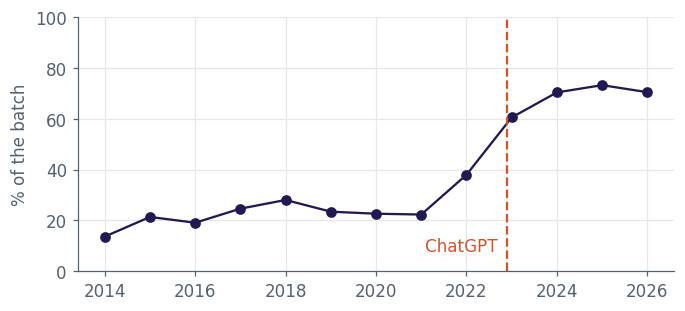

In [7]:
# @title Chart: AI as the core, by batch year { display-mode: "form" }
share = yc[yc["year"] >= 2014].groupby("year")["ai"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(share.index, share.values, "-o", color=NAVY)
ax.axvline(2022.9, color=ORANGE, ls="--"); ax.text(2022.7, 8, "ChatGPT", color=ORANGE, ha="right")
ax.set_ylabel("% of the batch"); ax.set_ylim(0, 100)
plt.show()

🤔 *This chart is the puzzle, not the answer. Stories A and B both predict this line. What do you need to know about these startups that the chart cannot show you? That is why the next steps exist.*

✏️ **Check by hand.** The chart is only as good as the labels. The next cell prints 30 random startups, without the model's answer.
It shows the first 280 characters, so look up the full text in `yc` if you are unsure.
Read them and decide yourselves: is AI the core? Then write `True` or `False` for each one, in the order shown, in the cell after it.

In [8]:
check_ai = yc[yc["year"] >= 2017].sample(30, random_state=8)[["name", "year", "text"]].reset_index(drop=True)
for r in check_ai.itertuples():
    print(f"{r.Index:2} {r.name} ({r.year:.0f}): {r.text[:280]}\n")

 0 Refactor (2024): Deploying secure and reliable AI agents across healthcare, retail,…. Refactor works closely with large organizations across healthcare, retail, and logistics to safely tackle their most ambitious AI use-cases in record time. We focus on building autonomous systems that call, clic

 1 Thera (2022): AI-Native Finance OS. Thera is an AI-native ecosystem of apps to run a modern business: global payroll, treasury, spend management, invoicing/payments.

Thera works with hundreds of the world's leading companies like Oceans, 20four7VA, Landed, Zendrop, Oneleet, Codingal and Mer

 2 CONUS (2026): The AI knowledge layer for medical devices. CONUS structures fragmented medical device information for surgeons. We combine manufacturer documentation, hospital protocols and medical research in one place, giving surgeons and MedTech teams reliable answers across products and pro

 3 Lumona (2024): AI-enabled search engine featuring insights from social media.. Lumona is an AI-enab

In [9]:
MY_AI = [
    True,   # 0  Refactor
    False,  # 1  Thera
    True,   # 2  CONUS
    True,   # 3  Lumona
    False,  # 4  CareerTu
    True,   # 5  Verihubs
    True,   # 6  Langfuse
    False,  # 7  Rocketable
    False,  # 8  Herald
    True,   # 9  Mem0
    False,  # 10 Village Labs
    True,   # 11 Aucert
    True,   # 12 ReasonBlocks
    True,   # 13 Aurelian
    True,   # 14 Godela
    False,  # 15 Terark
    False,  # 16 Integration Labs
    True,   # 17 Stilta
    False,  # 18 Aella
    False,  # 19 IronLedger.ai
    False,  # 20 Tablevibe
    False,  # 21 Swipe
    True,   # 22 Operon
    False,  # 23 Elayne
    False,  # 24 Gather
    False,  # 25 Tint
    True,   # 26 Panacea
    True,   # 27 Mercator
    True,   # 28 Hypnos
    False,  # 29 AccioJob
]  # ✏️ 30 times True or False, in the order above

In [10]:
model_ai = yc.set_index("name").loc[check_ai["name"], "ai"].tolist()
if len(MY_AI) == len(model_ai):
    print(f"agreement {accuracy_score(MY_AI, model_ai):.0%} · kappa {cohen_kappa_score(MY_AI, model_ai):.2f}")
    print(f"you say yes {np.mean(MY_AI):.0%} · the model says yes {np.mean(model_ai):.0%}")
else:
    print("Fill in MY_AI first.")

agreement 90% · kappa 0.80
you say yes 50% · the model says yes 60%


In [11]:
# Check the 3 Disagreements

check_ai["you"] = MY_AI
check_ai["model"] = model_ai
check_ai[check_ai["you"] != check_ai["model"]][["name", "year", "you", "model"]]

,name,year,you,model
1,Thera,2022.0,False,True
7,Rocketable,2025.0,False,True
19,IronLedger.ai,2025.0,False,True


---
# ✍️ Step 2 · Extract: what work does it really do?

**The smaller question.** What work does this product do for its customer, in plain words?

**Why this needs doing at all.** To compare work across years, you need descriptions of the work, and that is not what startups write. *AI-native platform for the future of work*
tells you nothing. There is a second reason, and it is the important one. We are measuring AI and the type of work separately. If the word "AI" stays in the text, step 3 tends to group
startups by how they talk about AI, and not by what they do. So we take it out.

**Why a small LLM.** This step needs new text, and the LLM is the only tool here that can write. The decision model only chooses, and a classifier only labels.

**Why only a sample.** The LLM is slow, and text costs more than a yes or no. Rewriting all startups would take about 40 minutes, and step 4 reaches the rest far more cheaply. So we take 200 startups per period, so that each period counts the same (100 on plan B).
That is the rule from the session: spend the LLM on a sample where you need text, and let cheaper models do the volume.

**What goes to the next step.** A column `task` with plain work for the sample.

✏️ **Your turn.** Write a Pydantic class `Work` with one field `task`, and the instruction `WORK_INSTRUCTION`. Template: notebook 2. Remember that the
model does not read the schema, so everything it needs goes into the instruction. Ask for a verb and an object in at most 8 plain words, about the concrete work and not the
technology or the marketing. Rule out words like AI, platform and solution, and give four or five examples of good answers.

In [13]:
class Work(BaseModel):
    task: str = Field(description="The concrete work the product does for its customer: "
                                  "a verb and an object, at most 8 plain words")

WORK_INSTRUCTION = '''You read a startup description and say what work the product does for its customer.
Answer with a verb and an object, in at most 8 plain words.
Describe the concrete work, not the technology and not the marketing.
Never use the words AI, artificial intelligence, platform, solution, agent, or powered.

Examples of good answers:
- Description: "AI-native finance OS for modern businesses" -> task: "runs payroll and pays company invoices"
- Description: "Conversational AI agent for 911 centers" -> task: "answers non-emergency calls for emergency services"
- Description: "Direct ordering software for restaurants" -> task: "takes online food orders for restaurants"
- Description: "AI-powered deepfake detection" -> task: "checks whether customer identity photos are real"
- Description: "Embedded insurance API for tech platforms" -> task: "sells insurance inside other companies' apps"
'''

In [14]:
sample = yc[yc["period"] != "2011-16"].groupby("period", observed=True).sample(200 if BACKEND == "ollama" else 100, random_state=7).reset_index(drop=True)
print(sample["text"].iloc[:5].map(lambda t: ask(WORK_INSTRUCTION, t, Work).task).tolist())

['creates realistic spoken audio for media', 'hires temporary workers and manages their pay', 'produces low-cost plant-based meat at high volumes', "books and finds children's activities for parents", 'manages money to help tech workers decide better finances']


✏️ *The cell above printed five answers. If they are too vague, improve `WORK_INSTRUCTION` and run both cells again, before you spend five minutes on all of them.*

In [15]:
t0 = time.time()
with ThreadPoolExecutor(2 if BACKEND == "ollama" else 1) as pool:
    sample["task"] = list(pool.map(lambda t: ask(WORK_INSTRUCTION, t, Work).task, sample["text"]))
sample[["name", "task"]].to_csv("step2_tasks.csv", index=False)
print(f"{(time.time() - t0) / 60:.1f} minutes")
sample[["name", "one_liner", "task"]].sample(10, random_state=2)

3.5 minutes


,name,one_liner,task
449,Luminal,Making AI run fast on any hardware.,compiles models to run faster on hardware
141,Headstart,Headstart uses Machine Learning to help companies decide on who to…,matches job seekers with ideal company roles
131,Cityfurnish,Cityfurnish - Commitment-free furniture rentals for a better you!,rents furniture and appliances for customers
311,Cohere,Support automation that's actually intelligent,resolves customer support issues quickly
176,LemonBox,"AI-generated personalized nutrition solutions, built for you daily.",creates custom daily supplement formulas for users
134,Path,Financial advisors for Gen-Z,manages college funds and builds credit
551,OpenInt,Open Source Embedded Product Integrations,connects software systems using simple code
152,DirectShifts,"Workforce platform to recruit, license, credential & manage clinicians","manages clinician hiring, licensing, and scheduling"
123,Probably Genetic,Patient Intelligence Platform for Genetic Disease,finds patients and connects them to treatments
317,DigiBuild,We buy & track building materials for construction companies.,buys and tracks building materials for construction


---
# 🗺️ Step 3 · Discover: which types of work exist?

**The smaller question.** Which types of work are there in this data?

**Why BERTopic.** Nobody has a list, and you do not want to invent one. A list from your head would build your expectations into the result. BERTopic finds groups from the texts
themselves, as in session 1.

**Why not something else.** A classifier and a decision model both need a list of categories, and that is exactly what is missing here. An LLM could suggest categories, but it reads only what you show it, and it cannot tell you how many startups fall into each.

**What is new.** The LLM names each topic. BERTopic sends it the keywords and a few typical documents, so naming takes one call per topic and not one per startup. This is another cheap use of
an LLM: a few calls, where text is needed.

**Your part.** The model groups, and you decide what the groups mean. Some startups fit no group at first, and `reduce_outliers` moves them to the closest topic when they are close enough. That judgement cannot be automated, and it is why step 3 ends with you.

We first run BERTopic on the raw descriptions and on the plain work, so you can see whether step 2 was worth it.

In [16]:
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance, OpenAI as LLMNames
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

embedder = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)

def topic_model(seed=42, names=False):
    aspects = {"Main": KeyBERTInspired(), "MMR": MaximalMarginalRelevance(diversity=0.4)}
    if names:
        aspects["Label"] = LLMNames(client, model=MODEL, nr_docs=8, prompt='''These startups do similar work:
[DOCUMENTS]
Keywords: [KEYWORDS]
Name the type of work in two to five plain words. Do not use the words AI or platform. Reply with the name only.''',
                                    delay_in_seconds=PAUSE, generator_kwargs={"temperature": 0, **EXTRA})
    return BERTopic(embedding_model=embedder, representation_model=aspects,
                    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0, metric="cosine", random_state=seed),
                    hdbscan_model=HDBSCAN(min_cluster_size=10, cluster_selection_method="leaf", prediction_data=True),
                    vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2)))

for name, column in [("raw descriptions", "text"), ("plain work", "task")]:
    topics, _ = topic_model().fit_transform(sample[column].tolist())
    topics = np.array(topics)
    print(f"{name:<18} {topics.max() + 1} topics, {(topics == -1).mean():.0%} without a topic")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

raw descriptions   13 topics, 40% without a topic
plain work         18 topics, 31% without a topic


🤔 *Compare the two lines above. Which text gave more topics, and which left fewer startups without a topic? What does that tell you about step 2?*
Now the real run on the plain work, this time with the LLM naming each topic.

In [17]:
docs = sample["task"].tolist()
embeddings = embedder.encode(docs, show_progress_bar=False)
model = topic_model(names=True)
topics, _ = model.fit_transform(docs, embeddings)
sample["topic"] = model.reduce_outliers(docs, topics, strategy="embeddings", embeddings=embeddings, threshold=0.45)
print(f"without a topic: {np.mean(np.array(topics) == -1):.0%} before, {(sample['topic'] == -1).mean():.0%} after reduce_outliers")

label = lambda t: model.topic_aspects_["Label"][t][0][0] if t >= 0 else "(no topic)"
table = pd.crosstab(sample["topic"], sample["period"], normalize="columns").round(3)
table.insert(0, "name", [label(t) for t in table.index])
table.insert(1, "n", sample["topic"].value_counts().reindex(table.index))
table.insert(2, "examples", [" · ".join(sample.loc[sample["topic"] == t, "task"].head(3)) for t in table.index])
table

without a topic: 31% before, 18% after reduce_outliers


period,name,n,examples,2017-19,2020-22,2023-26
topic,,,,,,
-1,(no topic),107,books and finds children's activities for parents · helps workers discover new paths to prosperity · sells electric planes to airlines,0.200,0.150,0.185
0,Business Financial Services,90,hires temporary workers and manages their pay · manages money to help tech workers decide better finances · provides security and insurance coverage for businesses,0.180,0.200,0.070
1,Software development automation and quality assurance,36,build live tools and automate team workflows · builds and runs JavaScript code quickly · runs tests in temporary environments for code changes,0.040,0.035,0.105
2,Data Processing and Analysis,39,creates visual interpretation tools for businesses · combines and moves business data easily · collects high-quality human data for research,0.020,0.085,0.090
3,Biotechnology and Therapeutics,26,screens patients for eye disease to prevent blindness · creates new antibody designs for drugs · predicts best treatments for autoimmune patients,0.060,0.055,0.015
4,Building management and construction services,27,provides corporate housing for young professionals · find building codes for construction projects · constructs houses using automated building systems,0.045,0.045,0.045
5,Food production and delivery,25,produces low-cost plant-based meat at high volumes · grows protein from waste for animal feed · sells vegan food and goods to customers,0.070,0.050,0.005
6,Video Content Creation and Media,23,creates realistic spoken audio for media · plays videos to help users sleep · provides video explanations for children's questions,0.040,0.050,0.025
7,Career and skill development,23,teaches parents how to develop young children · assesses candidates using real-world tests · matches people to jobs based on skills,0.070,0.030,0.015


✏️ **Name your types of work.** Merge the topics into **8 to 10 types** that make sense to you. Read the names and the examples, and do not
trust a name blindly: the LLM may call a group of security tools "property monitoring". In `MERGE` below, write each topic number with
your type name. Several numbers can share one type. Leave out topics you cannot interpret: those startups get no type here, and the
models in step 4 will label them.

`DEFINITIONS` gives each type one line, which the decision model will use in step 4. Do not add an *Other* option: when we tested this, the model chose it far too often. Without it, the model matched
labels made by careful reviewers on 79 % of startups, up from 67 %.

In [18]:
 MERGE = {
    0: "Finance and insurance",
    15: "Finance and insurance",
    1: "Software development tools",
    11: "Software development tools",
    2: "Data and ML infrastructure",
    9: "Data and ML infrastructure",
    3: "Healthcare and biotech",
    16: "Healthcare and biotech",
    17: "Healthcare and biotech",
    4: "Construction and logistics",
    13: "Construction and logistics",
    5: "Consumer commerce and food",
    8: "Consumer commerce and food",
    6: "Media and education",
    7: "Media and education",
    12: "Sales and customer management",
    10: "Sales and customer management",
    14: "Workflow automation",
}

DEFINITIONS = {
    "Finance and insurance": "Payments, payroll, lending, banking, insurance, and financial paperwork for people or businesses.",
    "Software development tools": "Tools that programmers use to write, test, run, deploy and host software and applications.",
    "Data and ML infrastructure": "Collecting, moving, storing and analysing data, and training or running machine learning models and their hardware.",
    "Healthcare and biotech": "Diagnosing and treating patients, developing drugs, and running medical clinics, billing and patient data.",
    "Construction and logistics": "Building, managing and maintaining physical buildings, and moving people or goods by road, air or sea.",
    "Consumer commerce and food": "Selling products, food or groceries directly to individual consumers, and producing food.",
    "Media and education": "Creating audio, video or written content, and teaching people skills, courses or helping them find careers.",
    "Sales and customer management": "Helping businesses find, sell to, talk to and keep their customers.",
    "Workflow automation": "Organising and automating everyday office work, tasks, requests and coordination for non-technical employees.",
}

In [19]:
sample["type"] = sample["topic"].map(MERGE)
print(sample["type"].value_counts(dropna=False))

type
NaN                              107
Finance and insurance            106
Healthcare and biotech            66
Data and ML infrastructure        58
Software development tools        57
Consumer commerce and food        56
Media and education               46
Sales and customer management     42
Construction and logistics        41
Workflow automation               21
Name: count, dtype: int64


---
# 🏷️ Step 4 · Scale: label every startup

**The smaller question.** Which type of work is each of the 5,500 startups?

**What changed.** After step 3 you have what was missing before: a list of types, and a sample with labels you have looked at yourselves. So two tools that could not help in step 3 can help now.

- **Classifier.** It learns from your labelled sample, as in session 1 and in notebook 3. It costs seconds. Its weak spot is that it only knows what is in 600 examples.
- **Decision model.** It needs no training, only your definitions. It takes about 12 minutes. Its weak spot is that it depends on how well you wrote them.

**Why try both.** Neither is better in general. It depends on your types and your definitions. You cannot know in advance, so you measure: you check both by hand and use the one that agrees with you more often.
That is the recipe from the session. With 40 startups, two or three answers can decide it, so if it is close, say so when you report your result.

**Why not the LLM.** It would take about 40 minutes more and it adds nothing you need here: you want a label, and no text.

**What goes to the next step.** A column `type` for every startup.

✏️ **Your turn: the classifier.** `X` holds the embeddings of your labelled sample, and `everything` holds those of all startups. Train a `LinearSVC` on `X` and `labelled["type"]`, print
its cross-validated accuracy, and put its predictions for all startups into `yc["type_classifier"]`. Template: section 7 of notebook 3.

In [20]:
labelled = sample.dropna(subset=["type"])
everything = embedder.encode(yc["text"].tolist(), batch_size=128, show_progress_bar=False)
position = dict(zip(yc["name"], range(len(yc))))
X = everything[[position[n] for n in labelled["name"]]]

In [21]:
clf = LinearSVC()
scores = cross_val_score(clf, X, labelled["type"], cv=5)
print(f"cross-validated accuracy: {scores.mean():.0%} (± {scores.std():.0%})")

clf.fit(X, labelled["type"])
yc["type_classifier"] = clf.predict(everything)
print(yc["type_classifier"].value_counts())

cross-validated accuracy: 69% (± 3%)
type_classifier
Finance and insurance            1205
Software development tools        746
Healthcare and biotech            671
Data and ML infrastructure        622
Sales and customer management     592
Media and education               580
Consumer commerce and food        555
Construction and logistics        490
Workflow automation                99
Name: count, dtype: int64


✏️ **Your turn: the decision model.** Write `work_type`, which asks one `choice` question with your `DEFINITIONS` as the criteria and returns the choice and the confidence.
Template: section 2 of notebook 3. The loop below it runs your function on every startup.

In [ ]:
def work_type(text):
    question = {"work": {"type": "choice",
                         "instructions": "What type of work does this startup's product do for its customer?",
                         "criteria": DEFINITIONS}}
    answer = decide(text, question)["work"]
    return answer["choice"], answer["confidence"]

In [23]:
if BACKEND == "ollama":
    work_type("warming up the model")
    t0 = time.time()
    with ThreadPoolExecutor(4) as pool:
        answers = list(pool.map(work_type, yc["text"]))
    yc["type_decision"] = [a[0] for a in answers]
    yc["confidence"] = [a[1] for a in answers]
    yc[["name", "type_classifier", "type_decision", "confidence"]].to_csv("step4_types.csv", index=False)
    print(f"{(time.time() - t0) / 60:.1f} minutes · the two agree on {(yc['type_classifier'] == yc['type_decision']).mean():.0%} of startups")
    print(f"confidence above 0.8: {(yc['confidence'] > 0.8).mean():.0%} of startups")
else:   # plan B: your definitions are new questions, so there are no saved answers. The classifier does this step alone
    yc["type_decision"] = yc["type_classifier"]
    print("Plan B: the decision model is not available here, so both columns hold the classifier's labels.")

12.0 minutes · the two agree on 51% of startups
confidence above 0.8: 43% of startups


✏️ **Check by hand.** The next cell prints 40 startups, without any model's answer, and your type names. Label each one with a type name, in the
order shown, in the cell after it.

In [24]:
check_type = yc[yc["period"] != "2011-16"].sample(40, random_state=9)[["name", "text"]].reset_index(drop=True)
for r in check_type.itertuples():
    print(f"{r.Index:2} {r.name}: {r.text[:240]}\n")
print(list(DEFINITIONS))

 0 Buy Me a Coffee: Helping creators monetize. Buy Me a Coffee is a fast and beautiful way to fund your creative work. Loved by over a million creators. ☕️

 1 Rational: First Zero-human Accounting Firm. Rational is building the first accounting firm with no humans. It's entirely run by our AI employees, who go from client intake to doing the books to filing with the IRS. We secure 90% cost reduction, 24/7 

 2 Aviro: Environments for Long Horizon Work. We design challenging worlds where AI models learn to explore and solve problems. We turn these worlds into post-training datasets and reinforcement learning environments to train the next frontier of AI.

 3 LemonLime: Fully automated growth for small business. LemonLime runs fully automated sales and marketing for small businesses.

Every morning, LemonLime finds you new leads and drafts personalized outreach, prepares branded content, and identifies u

 4 Peoplebox.ai: AI talent platform to hire, manage, and grow your people . People

In [25]:
MY_TYPES = [
    "Finance and insurance",          # 0  Buy Me a Coffee
    "Finance and insurance",          # 1  Rational
    "Data and ML infrastructure",     # 2  Aviro
    "Sales and customer management",  # 3  LemonLime
    "Workflow automation",            # 4  Peoplebox.ai
    "Consumer commerce and food",     # 5  matagora
    "Workflow automation",            # 6  Loop Support
    "Media and education",            # 7  PlayAI
    "Healthcare and biotech",         # 8  ReactWise
    "Sales and customer management",  # 9  Global Belly
    "Software development tools",     # 10 Chatter
    "Sales and customer management",  # 11 Ladder
    "Workflow automation",            # 12 Linc.
    "Consumer commerce and food",     # 13 222
    "Finance and insurance",          # 14 QuotaBook
    "Workflow automation",            # 15 Doe
    "Software development tools",     # 16 Loops
    "Construction and logistics",     # 17 Flightcaster
    "Sales and customer management",  # 18 Glowing.io
    "Finance and insurance",          # 19 Pivo Technology Inc
    "Media and education",            # 20 ideate.xyz
    "Sales and customer management",  # 21 Lizza
    "Software development tools",     # 22 Coasts
    "Finance and insurance",          # 23 Thyme
    "Software development tools",     # 24 Stacker
    "Finance and insurance",          # 25 Conviction
    "Finance and insurance",          # 26 SafetyWing
    "Workflow automation",            # 27 Spine AI
    "Consumer commerce and food",     # 28 Preki
    "Healthcare and biotech",         # 29 BeWell Digital
    "Finance and insurance",          # 30 Koywe
    "Media and education",            # 31 Lingt
    "Software development tools",     # 32 Autosana
    "Sales and customer management",  # 33 Native
    "Media and education",            # 34 DailyBooth
    "Finance and insurance",          # 35 Pibit.ai
    "Construction and logistics",     # 36 Polymath Robotics
    "Workflow automation",            # 37 Pactima
    "Sales and customer management",  # 38 rift
    "Finance and insurance",          # 39 Veltha
]

In [26]:
if len(MY_TYPES) == len(check_type):
    look = yc.set_index("name").loc[check_type["name"]]
    for c in ["type_classifier", "type_decision"]:
        print(f"{c:<16} agrees with you on {accuracy_score(MY_TYPES, look[c]):.0%} · kappa {cohen_kappa_score(MY_TYPES, look[c]):.2f}")
else:
    print("Fill in MY_TYPES first.")

type_classifier  agrees with you on 50% · kappa 0.42
type_decision    agrees with you on 68% · kappa 0.62


In [28]:
yc["type"] = yc["type_decision"]   # ✏️ pick the one that did better in your hand check

---
# 🧮 Step 5 · Answer the question

**The smaller question.** How much of the rise in AI happened inside the same types of work?

**Why no language model here.** Every startup now has two facts: is AI the core, and what type of work. What is left is counting. This is the step that turns two stories into two numbers,
and it needs no AI at all.

First the two pictures. Which types of work grew and shrank? And how far did AI spread inside each type?

In [29]:
d = yc[yc["period"].isin(["2017-19", "2023-26"])]
before, after = d[d["period"] == "2017-19"], d[d["period"] == "2023-26"]
types = sorted(d["type"].unique())
compare = pd.DataFrame({
    "share before": before["type"].value_counts(normalize=True).reindex(types).fillna(0),
    "share after": after["type"].value_counts(normalize=True).reindex(types).fillna(0),
    "AI before": before.groupby("type")["ai"].mean().reindex(types).fillna(0),
    "AI after": after.groupby("type")["ai"].mean().reindex(types).fillna(0)})
compare.sort_values("share after", ascending=False).style.format("{:.0%}")

,share before,share after,AI before,AI after
type,,,,
Workflow automation,12%,23%,35%,87%
Data and ML infrastructure,11%,22%,56%,72%
Software development tools,14%,20%,17%,56%
Finance and insurance,17%,11%,11%,53%
Sales and customer management,9%,9%,42%,74%
Healthcare and biotech,13%,6%,24%,71%
Media and education,9%,5%,25%,81%
Construction and logistics,6%,3%,12%,37%
Consumer commerce and food,11%,1%,10%,25%


**Shift-share** is a standard tool from economics for exactly this question. We compare 2017–19 with 2023–26. The share of startups with AI
as the core rose, and we split that rise into two parts. Each part is one of the two stories:

- **Within** fits story B, the same work with AI. A type of work stays the same, but more of it uses AI. For each type: `average share of startups in this type × change in its AI share`
- **Between** fits story A, different work. The mix moved towards types that already used more AI. For each type: `average AI share of this type × change in its share of startups`

"Average" means the average of the two periods. Add up each part over all types. The two parts add up to the total rise.

**A small example with two types.** Health has 80 % of startups before and 40 % after, with AI at 10 % and 20 %. Agents has 20 % before and 60 % after, with AI at
80 % and 90 %. Total AI share: 24 % before (0.8 × 10 + 0.2 × 80) and 62 % after (0.4 × 20 + 0.6 × 90), so a rise of 38 points.

- Within, average share × change in AI: health 0.6 × 10 points = 6, plus agents 0.4 × 10 points = 4, so **10 points**
- Between, average AI × change in share: health 15 points × (−0.4) = −6, plus agents 85 points × 0.4 = 34, so **28 points**

10 + 28 = 38. In this made-up case only 26 % of the rise happened inside the same types of work, so most of it is a move to different work.

The last part of the cell after your function draws the startups again at random, 500 times, to show how much the result could move by chance.

✏️ **Your turn.** Write `shift_share`. It takes a table like `compare` and returns within and between. The small example is your test: it must print 0.10 and 0.28.

In [30]:

def shift_share(table):
    avg_share = (table["share before"] + table["share after"]) / 2
    avg_ai = (table["AI before"] + table["AI after"]) / 2

    within = (avg_share * (table["AI after"] - table["AI before"])).sum()
    between = (avg_ai * (table["share after"] - table["share before"])).sum()
    return within, between

example = pd.DataFrame({"share before": [.8, .2], "share after": [.4, .6], "AI before": [.1, .8], "AI after": [.2, .9]}, index=["Health", "Agents"])
print(shift_share(example))

(np.float64(0.1), np.float64(0.28))


In [31]:
within, between = shift_share(compare)
print(f"AI share: {before['ai'].mean():.0%} → {after['ai'].mean():.0%}")
print(f"within types {within * 100:+.0f} points · between types {between * 100:+.0f} points")
print(f"so {within / (within + between):.0%} of the rise happened inside the same type of work")

runs = []
for seed in range(500):   # resample the startups to see how much this could move by chance
    b_ = before.sample(frac=1, replace=True, random_state=seed)
    a_ = after.sample(frac=1, replace=True, random_state=seed + 1000)
    t = pd.DataFrame({"share before": b_["type"].value_counts(normalize=True).reindex(types).fillna(0),
                      "share after": a_["type"].value_counts(normalize=True).reindex(types).fillna(0),
                      "AI before": b_.groupby("type")["ai"].mean().reindex(types).fillna(0),
                      "AI after": a_.groupby("type")["ai"].mean().reindex(types).fillna(0)})
    w, btw = shift_share(t)
    runs.append(w / (w + btw))
print(f"95 % of resamples between {np.percentile(runs, 2.5):.0%} and {np.percentile(runs, 97.5):.0%}")

AI share: 25% → 69%
within types +37 points · between types +7 points
so 85% of the rise happened inside the same type of work
95 % of resamples between 80% and 89%


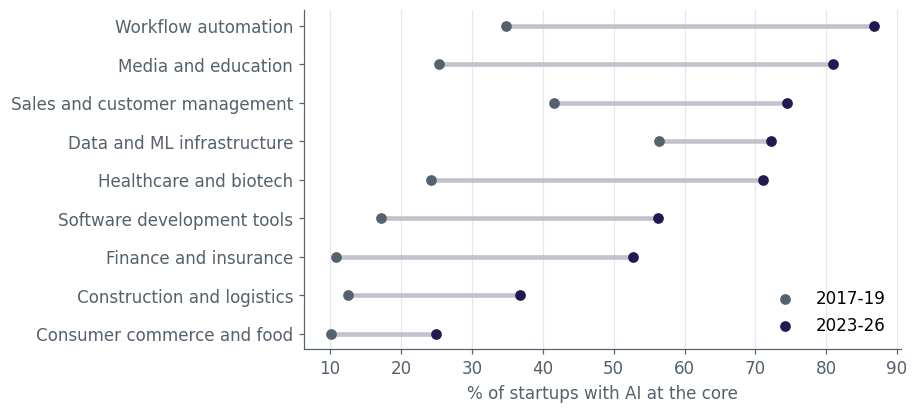

In [32]:
# @title Chart: where did AI spread? { display-mode: "form" }
c = compare.sort_values("AI after")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hlines(c.index, c["AI before"] * 100, c["AI after"] * 100, color=LAV, lw=3)
ax.scatter(c["AI before"] * 100, c.index, color=GREY, label="2017-19", zorder=3)
ax.scatter(c["AI after"] * 100, c.index, color=NAVY, label="2023-26", zorder=3)
ax.set_xlabel("% of startups with AI at the core"); ax.legend(); ax.grid(axis="y", visible=False)
plt.show()

🤔 *Go back to your prediction at the top. Were you right? Which part surprised you? Your answer depends on your own types and your own checks, so ask yourselves how far you trust it.*

---
# 🧩 Step 6 · Pull it together

You have reached an answer. Now make sure your group can tell the whole story, in this order:

1. **The question.** Why does it matter, and for whom? Explain the two stories, and what you predicted.
2. **From the big question to smaller questions.** How did you break it down, and why does each smaller question need its own tool?
3. **Each step.** Why this tool and not another? What did it hand to the next step? How long did it take?
4. **The answer.** Different work, or the same work with AI? Give your numbers and your best chart. Was your prediction right?
5. **What you found by hand.** What did your two checks by hand show? Name one case where a model was wrong and very confident.
6. **What you do not trust.** Give at least these five problems. Does a startup selling "AI agents for accountants" belong to AI or to finance, and how
   would your answer change with the other choice? Then, the descriptions are today's text, and a company from 2018 may have
   rewritten its description since then. And a startup may say AI is its core because that helps it raise money.
   Then, the split between within and between depends on how many types you chose: with a few broad types more of the rise looks like the same work, and with many narrow ones more looks like different work. It also depends on which years you compare.
   Finally, YC chooses who gets in, so a change may show what YC looks for as much as what founders want to do. Older companies that add AI are not in the new batches at all.

Tryfonas will tell you later how to submit.

1. Since ChatGPT, many more new startups put AI at the core of their product. We ask whether they do different work (Story A: new markets, such as AI agent tools) or the same work with AI (Story B: the same markets as before, such as bookkeeping, but done with AI).

This matters to founders and investors (is AI a new market, or is it coming into an existing one?), to workers (will AI reach existing jobs?) and to economists (Story B would make AI a general-purpose technology, like electricity).

Our prediction: a mix of both stories, without knowing which would dominate.





2. No model can answer the big question directly, so we split it into five smaller questions. Each one is a different kind of question and needs its own tool:

Is AI the core? It is a yes/no for 5,560 startups with no labels, so we used a decision model: fast, and it gives a probability.
What work does it do? This needs new text in plain words, without “AI”, so we used a small LLM on a sample of 600.
Which types of work exist? Nobody had a list, so BERTopic found the groups and we merged them into 9 types.
Which type is each startup? Now we had a list and many startups to sort, so we compared a classifier with a decision model and kept the decision model.
How much of the rise happened within types? This is just counting, so we used shift-share.



3. A decision model labelled all 5,560 startups as AI-core or not in 7.2 minutes, because it gives a fast yes/no and needs no labels. A small LLM then rewrote 600 sampled descriptions as plain work without “AI” (3.5 min). It is the only tool that can write text, but it is too slow to run on everything. BERTopic grouped these into topics, which we merged into 9 types of work (~2 min), since no list of types existed yet. To label all startups by type, we compared a classifier with a decision model and kept the decision model (12 min), because it agreed more often with our hand check (68% vs 50%). Finally, shift-share combined both labels by simple counting, in seconds.

4. Mostly the same work with AI (Story B). The share of startups with AI at the core rose from 25% to 69%, a rise of 44 points. Of these, 37 points happened within the same types of work and only 7 came from a shift between types. So 85% of the rise happened inside the same type of work (95% of resamples: 80–89%). The chart “Where did AI spread?” shows that AI grew in all 9 types, with large jumps in established areas such as finance (11% → 53%), healthcare (24% → 71%) and media and education (25% → 81%). Our prediction was partly right: both stories are present, but Story B clearly dominates.

5. In the AI check (30 startups), we agreed with the decision model on 90% (kappa 0.80), but the model said “yes” more often than we did (60% vs 50%). All three disagreements were cases where the model said “AI core” and we did not. Thera (0.76) and IronLedger.ai (0.69) use “AI” in their pitch but sell payroll and corporate cards. The most confident mistake was Rocketable (0.89): it buys software companies and replaces their teams with AI agents, so AI is used only inside the company, which our question explicitly excluded. In the type check (40 startups), the decision model agreed with us on 68% (kappa 0.62) and the classifier on only 50% (kappa 0.42), so we used the decision model.

In [33]:
yc[yc["name"].isin(["Thera", "Rocketable", "IronLedger.ai"])][["name", "ai_prob"]]

,name,ai_prob
3219,Thera,0.764616
4330,Rocketable,0.885250
4616,IronLedger.ai,0.690445


6. AI or finance? We placed “AI agents for accountants” by the work it does (finance), which pushes the rise towards “within”. Putting such startups in an AI type would move part of it to “between”. General AI agents such as Doe and Spine AI sit on this line in our Workflow automation type.
Today’s descriptions: a company from 2018 may have rewritten its text to sound more like AI, which would inflate the AI share in the early period.
AI as a label: some startups say AI is their core to raise money. Our model was fooled by this (Thera, IronLedger.ai).
Number of types and years: with our 9 fairly broad types, more of the rise looks like the same work. With more, narrower types, or other years, the 85% could change.
YC selection: the change may show what YC looks for, not only what founders want to build. Older firms that add AI are not in the new batches at all.

**Conclusion**

New startups are not mainly inventing new kinds of businesses. They are doing the same jobs as before (finance, healthcare, sales, education) and now build them around AI. About 85% of the rise in AI startups comes from AI spreading inside existing types of work, and only about 15% from startups moving into new areas. This suggests that AI behaves like electricity once did: a technology many industries adopt, not a separate sector. For founders and workers, the takeaway is that AI is likely to arrive in the markets and jobs that already exist. The result holds for Y Combinator startups only and depends partly on how we defined AI and the types of work.